# Lab 5: Put Uncertainty Into Your Project

---

## What this lab is

The last lab is about **your** project. You take the one number your project is built around and turn it into something a decision maker can trust: a range, a back-test, a scenario comparison and a figure for your paper. Everything you produce here can go straight into the Overleaf paper and the slides due on **6 December**.

* **Part A. Your key quantity.** Load it as a tidy table.
* **Part B. Back-test.** Hide the last years, project them with two models, count how often the truth falls inside the 90% band.
* **Part C. A range by simulation.** Pick the two most uncertain inputs of your pipeline, simulate, and find which matters most.
* **Part D. Scenarios.** At least two, compared with the interval width.
* **Part E. [OPTIONAL] One LLM-extracted variable**, evaluated as in Lab 5.
* **Part F. Communicate.** One fan chart and one paragraph for the paper.

## Conventions

* Same as before: **[QUAL]** 2-4 sentences, **[QUANT]** a number plus one sentence.
* If your project data are not ready, set `USE_DEMO = True`: the notebook runs on a demo series (synthetic steel-sector emissions) so you can build the code now and switch later. **Graded answers must use your project data.**
* Run **Kernel -> Restart & Run All** before submitting.

## Submission

Work in your **project group**. Push this notebook to your **project repository** in a folder `labs/`, and send the repo URL by email as before (1 email per group).

1. Full name: Oscar Moulet  Student ID: _______________
2. Full name: Adrien Labergere  Student ID: _______________
3. Full name: Lucas Magret Delord  Student ID: _______________
4. Full name: Louis Bettelli  Student ID: B00820941

**Project role (consultant / data scientist / risk analyst):**
**Key quantity (one sentence, with unit):**
**Repo URL:** https://github.com/Coachbet/moulet-labergere-magret_delord-bettelli

## Setup (given)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.float_format", "{:,.2f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25})
SEED = 42
rng = np.random.default_rng(SEED)

USE_DEMO = True   # set to False once your project data load below


def demo_series():
    # Synthetic sector emissions (MtCO2), 2005-2024: growth that slows down, plus noise.
    years = np.arange(2005, 2025)
    t = years - 2005
    trend = 900 + 70 * t - 1.9 * t**2
    noise = np.random.default_rng(7).normal(0, 35, len(t))
    return pd.DataFrame({"year": years, "value": trend + noise})

---
# PART A. Your key quantity

**Goal.** Create `series`: a DataFrame with columns `year` (int) and `value` (float), **one row per year**, sorted, for the single quantity your project is built around (e.g. sector emissions, a company's carbon cost, a portfolio's financed emissions, a capacity at risk). Also set `UNIT` (string) and `NAME` (string).

> **Hint.** If your project quantity is a panel (company x year), aggregate it for this lab (`groupby("year").value.sum()`). Keep at least **10 years** if you can.

In [2]:
if USE_DEMO:
    series, NAME, UNIT = demo_series(), "Demo sector emissions", "MtCO2"
else:
    # your code here: build `series`, NAME and UNIT from your project data
    pass
series.tail()

,year,value
15,2020,"1,546.84"
16,2021,"1,486.55"
17,2022,"1,524.88"
18,2023,"1,477.86"
19,2024,"1,498.97"


### Q1 [QUAL] What is it, and where can it go wrong?

In 3-4 sentences: what does your quantity measure, which **decision** in your value proposal depends on it, and list its main sources of uncertainty labelled **A** (aleatoric), **E** (epistemic) or **S** (scenario), as in Lab 3 Q4.

**Your answer (Q1):**

Our key quantity is the annual CO2 emissions of the steel sector, in MtCO2 (here the demo series, 2005-2024). The decision in our value proposal that depends on it is how large an abatement effort we need to reach the 2030 target, for example how many blast furnaces must be converted: a wrong baseline means over- or under-investing. Its main sources of uncertainty are:

* **A** (aleatoric): year-to-year noise in production, driven by the steel cycle.
* **E** (epistemic): the true 2030 emission factor of the process mix (BF-BOF vs EAF), and the choice of trend model.
* **S** (scenario): the policy and carbon-price path, which decides how fast furnaces are retired.

---
# PART B. Back-test before you trust a band

Session 4 showed a 95% band whose real coverage fell to 6%. Here you test your own.

## B1. Two models, one hold-out

**Goal.** Write `fit_predict(train, horizon, model, level=0.90)` that fits on `train` (columns `year`, `value`) and returns a DataFrame for the next `horizon` years with `year`, `mean`, `lo`, `hi` (a **prediction interval**). Implement:

* `model="linear"`: OLS on `value ~ year`, Student-t prediction interval (formula from session 4, appendix A);
* `model="loglinear"`: OLS on `log(value) ~ year`, interval computed on the log scale then exponentiated (only if all values > 0).

Then hold out the **last 5 years**, fit both models on the rest, and create `backtest` with the predictions and the actual values.

> **Hint.** Centre the year (`t = year - year.mean()`) for numerical stability. Leverage: `x0' (X'X)^-1 x0`.

In [3]:
def fit_predict(train, horizon, model, level=0.90):
    """Fit on `train` (columns year, value) and predict the next `horizon` years.
    Returns year, mean, lo, hi, where [lo, hi] is a prediction interval at `level`."""
    years = train["year"].to_numpy(dtype=float)
    y = train["value"].to_numpy(dtype=float)
    if model == "loglinear":
        if (y <= 0).any():
            raise ValueError("loglinear needs all values > 0")
        y = np.log(y)
    elif model != "linear":
        raise ValueError("model must be 'linear' or 'loglinear'")

    n = len(y)
    x_mean = years.mean()
    X = np.column_stack([np.ones(n), years - x_mean])        # centred year
    XtX_inv = np.linalg.inv(X.T @ X)
    beta = XtX_inv @ X.T @ y
    resid = y - X @ beta
    s2 = resid @ resid / (n - 2)                              # residual variance
    t_crit = stats.t.ppf(0.5 + level / 2, df=n - 2)

    future = years.max() + np.arange(1, horizon + 1)
    X0 = np.column_stack([np.ones(horizon), future - x_mean])
    mean = X0 @ beta
    leverage = np.einsum("ij,jk,ik->i", X0, XtX_inv, X0)      # x0' (X'X)^-1 x0
    half = t_crit * np.sqrt(s2 * (1 + leverage))              # prediction interval (not a CI)
    lo, hi = mean - half, mean + half
    if model == "loglinear":                                  # back to the original scale
        mean, lo, hi = np.exp(mean), np.exp(lo), np.exp(hi)   # (mean is then the median)
    return pd.DataFrame({"year": future.astype(int), "mean": mean, "lo": lo, "hi": hi})


H = 5                                                         # hold out the last 5 years
train, test = series.iloc[:-H], series.iloc[-H:]

parts = []
for m in ["linear", "loglinear"]:
    pred = fit_predict(train, H, m)
    pred["model"] = m
    parts.append(pred)

backtest = pd.concat(parts, ignore_index=True).merge(
    test.rename(columns={"value": "actual"}), on="year")
backtest["inside"] = (backtest["actual"] >= backtest["lo"]) & (backtest["actual"] <= backtest["hi"])
backtest[["model", "year", "actual", "mean", "lo", "hi", "inside"]]

,model,year,actual,mean,lo,hi,inside
0,linear,2020,"1,546.84","1,606.22","1,522.56","1,689.87",True
1,linear,2021,"1,486.55","1,649.91","1,564.31","1,735.50",False
2,linear,2022,"1,524.88","1,693.60","1,605.89","1,781.31",False
3,linear,2023,"1,477.86","1,737.29","1,647.30","1,827.28",False
4,linear,2024,"1,498.97","1,780.98","1,688.56","1,873.40",False
5,loglinear,2020,"1,546.84","1,656.18","1,520.90","1,803.49",True
6,loglinear,2021,"1,486.55","1,717.00","1,573.64","1,873.42",False
7,loglinear,2022,"1,524.88","1,780.06","1,627.92","1,946.41",False
8,loglinear,2023,"1,477.86","1,845.43","1,683.80","2,022.59",False
9,loglinear,2024,"1,498.97","1,913.21","1,741.31","2,102.07",False


### Q2 [QUANT + QUAL] Did your band hold?

(a) For each model, how many of the 5 held-out years fall inside the 90% band? (b) With 5 years, how many misses would make you doubt a 90% band? Use the binomial from session 6, station 3 (compute P(X >= k) for X ~ Bin(5, 0.1)). (c) Which model do you keep, and what does the gap between them tell you?

In [4]:
# (a) held-out years inside the 90% band
hits = backtest.groupby("model")["inside"].sum()
print("Held-out years inside the 90% band (out of 5):")
print(hits.to_string())

# (b) if the band were really 90%, a miss happens with p = 0.1: P(X >= k) for X ~ Bin(5, 0.1)
k = np.arange(0, 6)
binom_tail = pd.DataFrame({"k misses": k, "P(X >= k)": stats.binom.sf(k - 1, 5, 0.1)})
binom_tail["P(X >= k)"] = binom_tail["P(X >= k)"].map("{:.4f}".format)
binom_tail

Held-out years inside the 90% band (out of 5):
model
linear       1
loglinear    1


,k misses,P(X >= k)
0,0,1.0000
1,1,0.4095
2,2,0.0815
3,3,0.0086
4,4,0.0005
5,5,0.0000


**Your answer (Q2):**

**(a)** Only **1 of the 5** held-out years (2020) falls inside the 90% band, for both the linear and the log-linear model.

**(b)** If the band were really 90%, each year is a miss with probability 0.1. With 2 misses, P(X >= 2) = 0.08, which is already a bit suspicious, and with 3 misses P(X >= 3) = 0.009, so I would clearly doubt the band from 3 misses. We have 4 misses, and P(X >= 4) = 0.0005, so neither band is calibrated.

**(c)** I would keep the linear model, but only as the less bad one: its errors are smaller (in 2024 it predicts 1,781 against 1,499 observed, while the log-linear predicts 1,913) and its band is narrower. Both models overshoot because the demo series is concave: growth slows and then turns, and a straight line (or an exponential) cannot see it. The gap between the two models is also large compared with the band width, so the model choice is a bigger source of uncertainty than the noise the band captures. For this reason I do not use a trend for the projection in Part F.

## B2. [OPTIONAL] Rolling back-test

Repeat B1 with a **rolling origin**: for every cutoff year from the 10th year onwards, fit on the past and predict 1 to 3 years ahead. Report the coverage by horizon (1, 2, 3 years) for each model. This gives many more test points than a single hold-out.

In [5]:
# Rolling origin: train on the first `end` years (at least 10), predict 1 to 3 years ahead
rows = []
for end in range(10, len(series)):
    tr = series.iloc[:end]
    h_max = min(3, len(series) - end)               # only horizons for which the truth is known
    for m in ["linear", "loglinear"]:
        pred = fit_predict(tr, h_max, m)
        pred["model"] = m
        pred["horizon"] = pred["year"] - tr["year"].iloc[-1]
        rows.append(pred)

rolling = pd.concat(rows, ignore_index=True).merge(
    series.rename(columns={"value": "actual"}), on="year")
rolling["inside"] = (rolling["actual"] >= rolling["lo"]) & (rolling["actual"] <= rolling["hi"])

coverage = (rolling.groupby(["model", "horizon"])["inside"]
            .agg(coverage="mean", n_tests="count").reset_index())
coverage["coverage"] = 100 * coverage["coverage"]
coverage.rename(columns={"coverage": "coverage (%)"})

,model,horizon,coverage (%),n_tests
0,linear,1,40.00,10
1,linear,2,22.22,9
2,linear,3,0.00,8
3,loglinear,1,40.00,10
4,loglinear,2,11.11,9
5,loglinear,3,0.00,8


---
# PART C. A range by simulation

Your key quantity is computed from inputs (e.g. capacity x utilisation x emission factor, or emissions x carbon price x pass-through). Pick the **two inputs you are least sure about**.

**Goal.** Fill in `compute_quantity(input1, input2)` with your project formula (vectorised with NumPy), choose a distribution for each input with a **written justification**, and run `n = 5,000` draws for your target year. Report the median and 90% interval. Then run a **one-at-a-time sensitivity**: fix each input at its median in turn and report the relative half-width.

> **Demo.** 2030 emissions = production (Mt) x emission factor (tCO2/t). Production ~ Normal(800, 40); factor ~ Triangular(1.5, 1.85, 2.3).

In [6]:
N = 5_000
TARGET_YEAR = 2030


def compute_quantity(production, factor):
    """Demo formula: emissions (MtCO2) = production (Mt) x emission factor (tCO2/t)."""
    return production * factor


# Input 1, production ~ Normal(800, 40): the 2030 output is centred on current capacity and
# varies symmetrically with the steel cycle (about +/-5%), so a Normal is a natural choice.
production = rng.normal(800, 40, N)

# Input 2, factor ~ Triangular(1.5, 1.85, 2.3): we only know a plausible minimum, maximum and
# most likely value for the 2030 process mix (BF-BOF vs EAF), not a full distribution, so a
# Triangular is the usual choice; it is slightly skewed towards higher factors.
factor = rng.triangular(1.5, 1.85, 2.3, N)

draws = compute_quantity(production, factor)
q05, q50, q95 = np.percentile(draws, [5, 50, 95])
print(f"{TARGET_YEAR} {NAME}: median = {q50:,.0f} {UNIT}, 90% interval = [{q05:,.0f}, {q95:,.0f}] {UNIT}")


# One-at-a-time sensitivity: fix one input at its median, keep the other random
def summarise(x):
    lo, med, hi = np.percentile(x, [5, 50, 95])
    return med, lo, hi, 100 * (hi - lo) / 2 / med      # relative half-width in %


cases = {
    "Both inputs random": draws,
    "Production fixed at its median": compute_quantity(np.median(production), factor),
    "Factor fixed at its median": compute_quantity(production, np.median(factor)),
}
sens = pd.DataFrame([summarise(x) for x in cases.values()], index=list(cases),
                    columns=["median", "5%", "95%", "relative half-width (%)"])
sens

2030 Demo sector emissions: median = 1,497 MtCO2, 90% interval = [1,268, 1,770] MtCO2


,median,5%,95%,relative half-width (%)
Both inputs random,"1,496.76","1,268.21","1,770.49",16.78
Production fixed at its median,"1,502.28","1,291.15","1,734.82",14.77
Factor fixed at its median,"1,502.28","1,375.88","1,624.02",8.26


### Q3 [QUANT + QUAL] Which input drives the range?

(a) Median and 90% interval for your target year. (b) Which input, once fixed, shrinks the interval most? Is it **aleatoric** or **epistemic**? (c) If you had one more week, what data would you collect to shrink it, and which part of the range would remain whatever you do?

**Your answer (Q3):**

**(a)** For 2030 the median is **1,497 MtCO2** and the 90% interval is **[1,268, 1,770] MtCO2**.

**(b)** Fixing the **emission factor** shrinks the interval the most: the relative half-width goes from 16.8% to 8.3%, against 14.8% when production is fixed. The factor is mainly **epistemic**, because we simply do not know the 2030 process mix and better data would narrow it. Production is closer to **aleatoric**, since it follows the steel cycle.

**(c)** With one more week I would collect plant-level emission intensities by process route (BF-BOF and EAF) and the announced furnace retirements up to 2030, to narrow the factor range. What would remain is the variability of production (about 8% relative half-width when the factor is fixed) and the scenario uncertainty, which no data collection can remove.

---
# PART D. Scenarios

**Goal.** Define at least **two scenarios** relevant to your role (e.g. an NGFS-style orderly vs delayed transition, a carbon price of 50 vs 150 USD/t, 30% of blast furnaces retired). Implement each as a change to the inputs of Part C, rerun the simulation, and create a table `scen` with the median and 90% interval per scenario.

In [7]:
# Scenarios are changes to the inputs of Part C. The baseline reuses the Part C draws.
# Orderly transition: 30% of blast-furnace output is retired and replaced by EAF. Taking
# about 2.2 tCO2/t for BF-BOF and 0.7 for EAF, this lowers the average factor by roughly
# 0.3 tCO2/t, so the three Triangular parameters are shifted down by 0.3. Production is kept
# the same so that only the transition changes.
scenario_draws = {
    "Baseline (no retirement)": draws,
    "Orderly transition (30% of BF retired)": compute_quantity(
        production, rng.triangular(1.5 - 0.3, 1.85 - 0.3, 2.3 - 0.3, N)),
}

rows = []
for name, d in scenario_draws.items():
    lo, med, hi = np.percentile(d, [5, 50, 95])
    rows.append({"scenario": name, "median": med, "5%": lo, "95%": hi, "width": hi - lo})
scen = pd.DataFrame(rows).set_index("scenario")

gap = scen["median"].max() - scen["median"].min()
print(f"Largest gap between scenario medians: {gap:,.0f} {UNIT}")
print(f"Interval width within one scenario:   {scen['width'].min():,.0f} to {scen['width'].max():,.0f} {UNIT}")
scen

Largest gap between scenario medians: 238 MtCO2
Interval width within one scenario:   477 to 502 MtCO2


,median,5%,95%,width
scenario,,,,
Baseline (no retirement),"1,496.76","1,268.21","1,770.49",502.29
Orderly transition (30% of BF retired),"1,258.63","1,038.61","1,515.21",476.60


### Q4 [QUANT + QUAL] Scenario gap vs interval width

Compare the largest **gap between scenario medians** with the **width** of the interval within one scenario. Which is bigger? What does that mean for how you present your result (one fan chart, or one band per scenario)?

**Your answer (Q4):**

The largest gap between scenario medians is **238 MtCO2** (1,497 vs 1,259), while the 90% interval inside one scenario is **477-502 MtCO2** wide. So the interval width is about twice the gap, and the two bands overlap a lot (the baseline 5% value, 1,268, is below the orderly 95% value, 1,515). This means that the scenario choice moves the median but does not clearly separate the outcomes. I would therefore not present one single band: I would show one band per scenario on the same fan chart, so that the reader sees both the shift and the overlap, and I would not claim a precise saving of 238 MtCO2.

---
# PART E. [OPTIONAL] One LLM-extracted variable

If your project uses a variable you could only get from text (targets, ownership shares, plant start dates…):

1. Extract it with an LLM for your companies, using the schema and parser pattern of Lab 5.
2. Label **at least 10** cases by hand (your gold sample).
3. Report accuracy with a **Beta(1,1) 90% interval** and the list of errors by type.

### Q5 [QUANT + QUAL] (optional)

Accuracy with interval, main error type, and one sentence on how the errors could bias your key quantity.

In [8]:
import json, os, re

# --- 1. The variable, its schema and the prompt (EDIT VARIABLE/PROMPT for YOUR variable) ---
VARIABLE = "net-zero target year"
PROMPT = (
    f"Extract the {VARIABLE} from the text below. "
    'Answer with JSON only, with exactly these keys: {"value": <number or null>, "evidence": <short quote or null>}. '
    "Use null if the text does not state it. Do not guess.\n\nText:\n"
)
MODEL = "claude-sonnet-5-5"


# --- 2. Parser: turn the raw LLM answer into (value, error) ---
def parse_llm_json(raw):
    cleaned = re.sub(r"^```(?:json)?|```$", "", raw.strip(), flags=re.M).strip()
    try:
        obj = json.loads(cleaned)
    except json.JSONDecodeError:
        return None, "parse error"
    if not isinstance(obj, dict) or "value" not in obj:
        return None, "schema error"
    return obj["value"], None


def extract(text, client):
    msg = client.messages.create(model=MODEL, max_tokens=200,
                                 messages=[{"role": "user", "content": PROMPT + text}])
    return parse_llm_json(msg.content[0].text)


# --- 3. Comparison with the hand labels ---
def is_null(x):
    return x is None or str(x).strip().lower() in {"", "null", "none", "nan"}


def same(pred, gold):
    if is_null(pred) or is_null(gold):
        return is_null(pred) and is_null(gold)
    try:
        return bool(np.isclose(float(pred), float(gold)))
    except (TypeError, ValueError):
        return str(pred).strip().lower() == str(gold).strip().lower()


def error_type(pred, gold, err):
    if isinstance(err, str):           # parse / schema error (NaN when there was none)
        return err
    if is_null(pred):
        return "missed value"
    return "invented value" if is_null(gold) else "wrong value"


# --- 4. Run on the gold sample: gold_sample.csv with columns id, text, gold (>= 10 rows, labelled by hand) ---
GOLD_PATH = Path("gold_sample.csv")
try:
    from dotenv import load_dotenv
    load_dotenv()                      # reads ANTHROPIC_API_KEY from a local .env file
except ImportError:
    pass

if not GOLD_PATH.exists():
    print("Part E skipped: create gold_sample.csv (copy gold_sample_template.csv) with at least 10 hand-labelled cases.")
elif not os.environ.get("ANTHROPIC_API_KEY"):
    print("Part E skipped: set ANTHROPIC_API_KEY (in your environment or in a .env file).")
else:
    from anthropic import Anthropic
    gold_df = pd.read_csv(GOLD_PATH)
    assert len(gold_df) >= 10, "Label at least 10 cases by hand."
    client = Anthropic()
    results = [extract(t, client) for t in gold_df["text"]]
    gold_df["pred"] = [r[0] for r in results]
    gold_df["err"] = [r[1] for r in results]
    gold_df["correct"] = [same(p, g) for p, g in zip(gold_df["pred"], gold_df["gold"])]

    n, k = len(gold_df), int(gold_df["correct"].sum())
    lo, hi = stats.beta.ppf([0.05, 0.95], 1 + k, 1 + n - k)       # Beta(1,1) prior -> Beta(1+k, 1+n-k)
    print(f"Accuracy: {k}/{n} = {k / n:.0%}, 90% interval [{lo:.0%}, {hi:.0%}]")

    errors = gold_df[~gold_df["correct"]].copy()
    errors["error type"] = [error_type(p, g, e) for p, g, e in zip(errors["pred"], errors["gold"], errors["err"])]
    print("\nErrors by type:")
    print(errors["error type"].value_counts().to_string())
    print(errors[["id", "gold", "pred", "error type"]].to_string(index=False))

Part E skipped: create gold_sample.csv (copy gold_sample_template.csv) with at least 10 hand-labelled cases.


**Your answer (Q5):**

_(optional: to be written once `gold_sample.csv` is filled in and the cell above has produced the accuracy and the error list)_

---
# PART F. Communicate

## F1. The figure for your paper

**Goal.** One fan chart: history as a line, then for your target years the median and the **50% and 90%** bands, one colour per scenario (at least the baseline). Label the axes with units, state the scenario in the legend, and save it as `fig_uncertainty.png` for Overleaf.

> **Hint.** Use the Part C/D draws for the target year and widen the bands from today's value to that year, or simulate the path year by year. Do not use a trend that failed the back-test in Part B. `plt.fill_between(...)`.

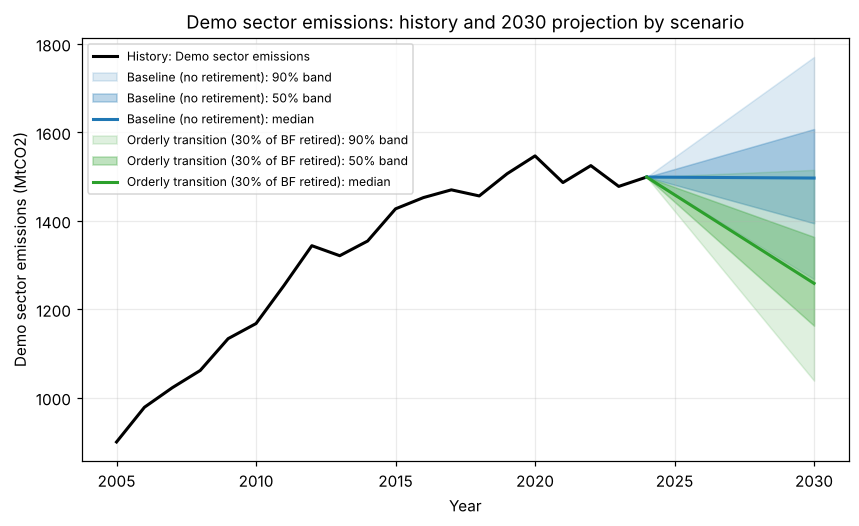

In [9]:
last_year, last_value = int(series["year"].iloc[-1]), series["value"].iloc[-1]
path_years = np.arange(last_year, TARGET_YEAR + 1)
frac = (path_years - last_year) / (TARGET_YEAR - last_year)   # 0 today -> 1 in the target year


def widen(q):
    # the band starts at today's value and widens linearly to the Part C/D quantile in 2030
    return last_value + (q - last_value) * frac


colors = ["tab:blue", "tab:green"]
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(series["year"], series["value"], color="black", lw=2, label=f"History: {NAME}")
for (name, d), c in zip(scenario_draws.items(), colors):
    p5, p25, p50, p75, p95 = np.percentile(d, [5, 25, 50, 75, 95])
    ax.fill_between(path_years, widen(p5), widen(p95), color=c, alpha=0.15, label=f"{name}: 90% band")
    ax.fill_between(path_years, widen(p25), widen(p75), color=c, alpha=0.30, label=f"{name}: 50% band")
    ax.plot(path_years, widen(p50), color=c, lw=2, label=f"{name}: median")
ax.set_xlabel("Year")
ax.set_ylabel(f"{NAME} ({UNIT})")
ax.set_title(f"{NAME}: history and {TARGET_YEAR} projection by scenario")
ax.legend(fontsize=8, loc="upper left")
fig.savefig("fig_uncertainty.png", dpi=200, bbox_inches="tight")
plt.show()

## F2. The paragraph for your paper

### Q6 [QUAL] About 120 words

Write the **uncertainty and limitations** paragraph of your Overleaf paper. Include: the scenario and horizon, the median and 90% interval, the back-test result (how many held-out years fell inside), the input that drives the range, the largest **scenario** gap, and one limitation of your method. Use one calibrated word from the IPCC scale.

### Q7 [QUAL] One sentence for your slides

Finish this sentence for your role's value proposal: *"Because the range is this wide, the decision that changes is …"*

**Your answer (Q6):**

We project 2030 sector emissions under two scenarios. In the baseline (no furnace retirement) the median is 1,497 MtCO2, and it is very likely, under our input assumptions, that the value lies between 1,268 and 1,770 MtCO2 (90% interval). In the orderly transition, with 30% of blast furnaces retired, the median falls to 1,259 MtCO2 [1,039-1,515]. The largest scenario gap, 238 MtCO2, is smaller than the width of one interval (about 480-500 MtCO2). The emission factor drives the range: fixing it halves the relative half-width from 16.8% to 8.3%. In the back-test, only 1 of 5 held-out years fell inside the 90% band of each trend model, so we did not use a trend. A limitation is that the two inputs are assumed independent and their distributions are expert guesses, not fitted to data.

**Your answer (Q7):**

*"Because the range is this wide, the decision that changes is **whether we commit to a single 2030 target figure or plan the abatement investment against the whole range, starting with the actions that narrow the emission factor**."*